# Funktionen mehrerer Veränderlicher VII: Extrema ohne Nebenbedingungen

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitt 2.8.1)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/07_extrema_ohne_nebenbedingungen.ipynb)

**Inhalt**


1. Definition 2.8.1.1 und Satz 2.8.1.2: lokale Extrema und stationäre Punkte
2. Beispiele 2.8.1.3 und 2.8.1.4: stationäre Punkte bestimmen
3. Definition 2.8.1.5 und Beispiel 2.8.1.6: die Hesse-Matrix
4. Sätze 2.8.1.7 und 2.8.1.8: hinreichende Bedingung (Eigenwerte und Determinante)
5. Beispiel 2.8.1.9: vier stationäre Punkte klassifizieren
6. Zusammenhang mit der Taylorentwicklung (interaktiv)
7. Satz 2.8.1.10 und Beispiel 2.8.1.11: Hurwitz-Kriterium, ein Beispiel mit drei Variablen
8. Satz 2.8.1.12 und Beispiel 2.8.1.13: globale Extrema auf einem Rechteck, Extrema auf dem Rand


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax


def klassifiziere(f, punkt, variablen=(x, y)):
    """Klassifiziert einen stationären Punkt über die Eigenwerte der Hesse-Matrix (Satz 2.8.1.7)."""
    subs = dict(zip(variablen, punkt))
    H = sp.hessian(f, variablen).subs(subs)
    ew = [sp.nsimplify(e) for e in H.eigenvals(multiple=True)]
    if all(e > 0 for e in ew):
        art = 'lokales Minimum (positiv definit)'
    elif all(e < 0 for e in ew):
        art = 'lokales Maximum (negativ definit)'
    elif any(e > 0 for e in ew) and any(e < 0 for e in ew):
        art = 'Sattelpunkt (indefinit)'
    else:
        art = 'keine Entscheidung (semidefinit)'
    return H, ew, art

## 1. Definition 2.8.1.1 und Satz 2.8.1.2

$f:D\to\mathbb{R}$, $D\subseteq\mathbb{R}^n$, hat in $x_0\in D$ ein **lokales Maximum** (Minimum), wenn es eine Umgebung $U_\varepsilon(x_0)$ mit einem $\varepsilon > 0$ gibt, so dass $f(x)\le f(x_0)$ ($f(x)\ge f(x_0)$) für alle $x\in U_\varepsilon(x_0)\cap D$. Gilt die Ungleichung für alle $x\in D$, ist das Extremum **global**.

**Notwendige Bedingung (Satz 2.8.1.2):** Ist $f$ im Inneren von $D$ differenzierbar und $x_0$ ein innerer Punkt mit lokalem Extremum, so gilt
$$f_{x_1}(x_0) = \dots = f_{x_n}(x_0) = 0,\quad\text{d. h.}\quad \operatorname{grad} f(x_0) = 0.$$
Solche Punkte heißen **stationäre Punkte**. Die Bedingung ist nicht hinreichend: Auch ein Sattelpunkt ist stationär.

Die Grafik zeigt eine Fläche mit einem globalen Maximum, einem lokalen Maximum und einem Sattelpunkt dazwischen.

globales Maximum bei (-1.000,  0.000),  f = 2.0002
lokales Maximum  bei ( 1.289,  0.299),  f = 1.2095
Sattelpunkt      bei ( 0.357,  0.177),  f = 0.5732


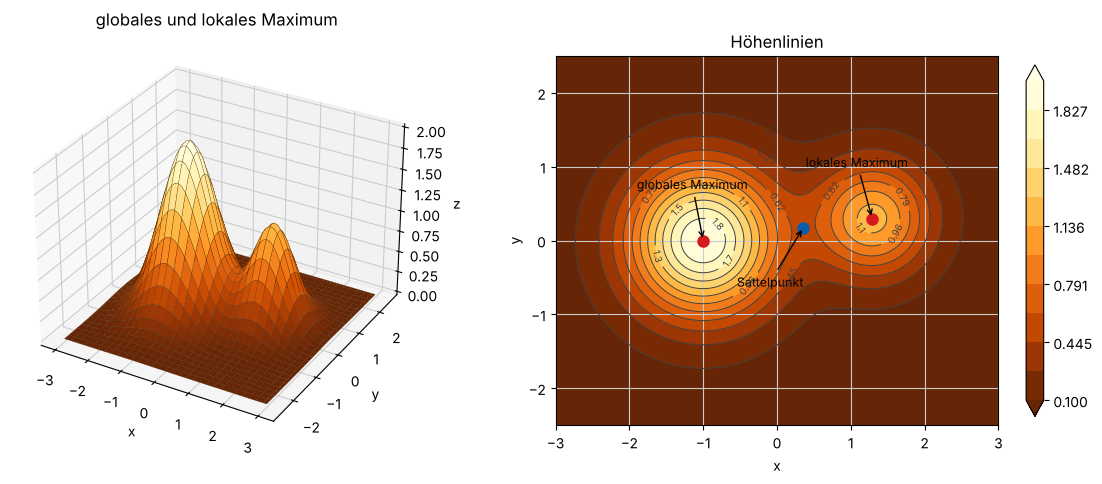

In [2]:
def berg(X, Y):
    return 2*np.exp(-((X + 1)**2 + Y**2)) + 1.2*np.exp(-((X - 1.3)**2 + (Y - 0.3)**2)/0.6)


fig = plt.figure(figsize=(12, 4.8))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
flaeche(berg, (-3, 3), (-2.5, 2.5), ax=ax1, titel='globales und lokales Maximum')
ax2 = fig.add_subplot(1, 2, 2)
hoehenlinien(berg, (-3, 3), (-2.5, 2.5), ax=ax2, niveaus=np.linspace(0.1, 2, 12), titel='Höhenlinien')
# stationäre Punkte numerisch
from scipy.optimize import root
gx = lambda p: [(berg(p[0] + 1e-6, p[1]) - berg(p[0] - 1e-6, p[1]))/2e-6,
                (berg(p[0], p[1] + 1e-6) - berg(p[0], p[1] - 1e-6))/2e-6]
for start, name in [((-1, 0), 'globales Maximum'), ((1.3, 0.3), 'lokales Maximum'), ((0.6, 0.15), 'Sattelpunkt')]:
    p = root(gx, start).x
    ax2.plot(*p, 'o', color=ROT if 'Max' in name else BLAU, ms=8)
    ax2.annotate(name, p, (p[0] - 0.9, p[1] - 0.8 if 'Sattel' in name else p[1] + 0.7), fontsize=9,
                 arrowprops=dict(arrowstyle='->'))
    print(f'{name:16s} bei ({p[0]: .3f}, {p[1]: .3f}),  f = {berg(*p):.4f}')
plt.tight_layout(); plt.show()

## 2. Beispiele 2.8.1.3 und 2.8.1.4

**Beispiel 2.8.1.3:** $f(x,y) = x^2 + y^2$ hat $f_x = 2x$, $f_y = 2y$. Einziger stationärer Punkt ist $(0,0)$, und wegen $f\ge 0 = f(0,0)$ liegt dort ein (globales) Minimum.

**Beispiel 2.8.1.4:** $f(x,y) = 2x^2 - xy + y^2 + 9x - 4y + 3$. Aus
$$f_x = 4x - y + 9 = 0,\qquad f_y = -x + 2y - 4 = 0$$
folgt mit $x = 2y - 4$ aus der zweiten Gleichung $7y - 7 = 0$, also $y = 1$, $x = -2$. Ob $(-2,1)$ ein Maximum, Minimum oder Sattelpunkt ist, entscheidet Satz 2.8.1.2 nicht.

In [3]:
f283 = x**2 + y**2
print('Beispiel 2.8.1.3: stationäre Punkte', sp.solve([sp.diff(f283, x), sp.diff(f283, y)], [x, y], dict=True))

f284 = 2*x**2 - x*y + y**2 + 9*x - 4*y + 3
grad284 = [sp.diff(f284, v) for v in (x, y)]
display(grad284)
stat = sp.solve(grad284, [x, y], dict=True)
print('Beispiel 2.8.1.4: stationäre Punkte', stat)
pruefe('Skript-Ergebnis x = -2', stat[0][x] + 2)
pruefe('Skript-Ergebnis y = 1', stat[0][y] - 1)

Beispiel 2.8.1.3: stationäre Punkte [{x: 0, y: 0}]


Beispiel 2.8.1.4: stationäre Punkte [{x: -2, y: 1}]
Probe Skript-Ergebnis x = -2: Residuum = 0  -> ok
Probe Skript-Ergebnis y = 1: Residuum = 0  -> ok


## 3. Definition 2.8.1.5 und Beispiel 2.8.1.6: die Hesse-Matrix

Die **Hesse-Matrix** enthält alle zweiten partiellen Ableitungen:
$$H_f(x) = \begin{pmatrix} f_{x_1x_1}(x) & \cdots & f_{x_1x_n}(x)\\ \vdots & \ddots & \vdots\\ f_{x_nx_1}(x) & \cdots & f_{x_nx_n}(x)\end{pmatrix}.$$
Sind die zweiten Ableitungen stetig, ist sie nach dem Satz von Schwarz symmetrisch.

**Beispiel 2.8.1.6:** Für $f(x,y) = \dfrac{\ln x}{x\cdot y}$ ($x > 0$, $y\neq 0$) ergibt das Skript
$$f_{xx} = \frac{2\ln x - 3}{x^3y},\quad f_{xy} = f_{yx} = \frac{\ln x - 1}{x^2y^2},\quad f_{yy} = \frac{2\ln x}{xy^3},\qquad H_f(1,2) = \begin{pmatrix} -\tfrac{3}{2} & -\tfrac{1}{4}\\ -\tfrac{1}{4} & 0\end{pmatrix}.$$

In [4]:
xp, yn = sp.symbols('x y', positive=True)
f286 = sp.log(xp)/(xp*yn)
H286 = sp.hessian(f286, (xp, yn))
display(sp.simplify(H286))
pruefe('f_xx laut Skript', H286[0, 0] - (2*sp.log(xp) - 3)/(xp**3*yn))
pruefe('f_xy laut Skript', H286[0, 1] - (sp.log(xp) - 1)/(xp**2*yn**2))
pruefe('f_yy laut Skript', H286[1, 1] - 2*sp.log(xp)/(xp*yn**3))
pruefe('Symmetrie (Satz von Schwarz)', H286 - H286.T)
H12 = H286.subs({xp: 1, yn: 2})
display(Markdown('$H_f(1,2) =$'), H12)
pruefe('H_f(1,2) laut Skript', H12 - sp.Matrix([[-sp.Rational(3, 2), -sp.Rational(1, 4)], [-sp.Rational(1, 4), 0]]))

⎡2⋅log(x) - 3  log(x) - 1⎤
⎢────────────  ──────────⎥
⎢     3           2  2   ⎥
⎢    x ⋅y        x ⋅y    ⎥
⎢                        ⎥
⎢ log(x) - 1    2⋅log(x) ⎥
⎢ ──────────    ──────── ⎥
⎢    2  2            3   ⎥
⎣   x ⋅y          x⋅y    ⎦

Probe f_xx laut Skript: Residuum = 0  -> ok
Probe f_xy laut Skript: Residuum = 0  -> ok
Probe f_yy laut Skript: Residuum = 0  -> ok
Probe Symmetrie (Satz von Schwarz): Residuum = Matrix([[0, 0], [0, 0]])  -> ok


$H_f(1,2) =$

⎡-3/2  -1/4⎤
⎢          ⎥
⎣-1/4   0  ⎦

Probe H_f(1,2) laut Skript: Residuum = Matrix([[0, 0], [0, 0]])  -> ok


## 4. Sätze 2.8.1.7 und 2.8.1.8: hinreichende Bedingung

Sei $f$ zweimal stetig differenzierbar und $\operatorname{grad} f(x_0) = 0$. Dann gilt (Satz 2.8.1.7):

| $H_f(x_0)$ | Eigenwerte | Folgerung |
| --- | --- | --- |
| positiv definit | alle $> 0$ | lokales Minimum |
| negativ definit | alle $< 0$ | lokales Maximum |
| indefinit | positive und negative | Sattelpunkt |
| semidefinit, nicht definit | ein Eigenwert $= 0$ | keine Entscheidung |

Für $n = 2$ (Satz 2.8.1.8) genügt die Determinante $\Delta(x_0) = f_{xx}f_{yy} - f_{xy}^2 = \lambda_1\lambda_2$: $\Delta > 0$ und $f_{xx} > 0$ ergibt ein Minimum, $\Delta > 0$ und $f_{xx} < 0$ ein Maximum, $\Delta < 0$ einen Sattelpunkt, $\Delta = 0$ keine Entscheidung.

**Fortsetzung von Beispiel 2.8.1.4:** $f_{xx} = 4$, $f_{xy} = -1$, $f_{yy} = 2$, also $\Delta(-2,1) = 8 - 1 = 7 > 0$ und $f_{xx} > 0$: lokales Minimum mit $f(-2,1) = -8$.

⎡4   -1⎤
⎢      ⎥
⎣-1  2 ⎦

Eigenwerte: [sqrt(2) + 3, 3 - sqrt(2)]  -> lokales Minimum (positiv definit)
Probe Δ(-2,1) = 7: Residuum = 0  -> ok
Probe f(-2,1) = -8: Residuum = 0  -> ok


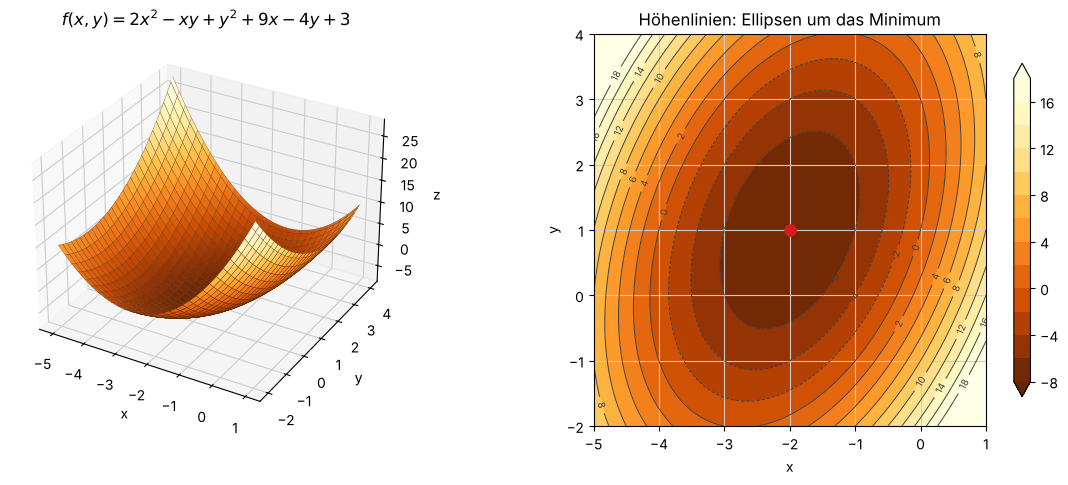

In [5]:
H, ew, art = klassifiziere(f284, (-2, 1))
display(H)
print('Eigenwerte:', ew, ' ->', art)
pruefe('Δ(-2,1) = 7', H.det() - 7)
pruefe('f(-2,1) = -8', f284.subs({x: -2, y: 1}) + 8)

f284n = sp.lambdify((x, y), f284, 'numpy')
fig = plt.figure(figsize=(12, 4.8))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
flaeche(f284n, (-5, 1), (-2, 4), ax=ax1, titel='$f(x,y) = 2x^2 - xy + y^2 + 9x - 4y + 3$')
ax2 = fig.add_subplot(1, 2, 2)
hoehenlinien(f284n, (-5, 1), (-2, 4), ax=ax2, niveaus=np.arange(-8, 20, 2), titel='Höhenlinien: Ellipsen um das Minimum')
ax2.plot(-2, 1, 'o', color=ROT, ms=8)
plt.tight_layout(); plt.show()

## 5. Beispiel 2.8.1.9

Bestimmen und klassifizieren Sie die Extrema von $f(x,y) = \tfrac{1}{3}x^3 - x^2 + y^3 - 12y$.

$f_x = x^2 - 2x = x(x-2)$ und $f_y = 3y^2 - 12 = 3(y^2 - 4)$ liefern die Kandidaten $(0,-2)$, $(0,2)$, $(2,-2)$, $(2,2)$. Mit $f_{xx} = 2x - 2$, $f_{xy} = 0$, $f_{yy} = 6y$ ist $\Delta(x,y) = (2x-2)\cdot 6y$:

| Punkt | $\Delta$ | $f_{xx}$ | Art |
| --- | --- | --- | --- |
| $(0,-2)$ | $24$ | $-2$ | Hochpunkt, $f = 16$ |
| $(0,2)$ | $-24$ | | Sattelpunkt |
| $(2,2)$ | $24$ | $2$ | Tiefpunkt, $f = -\tfrac{52}{3}$ |
| $(2,-2)$ | $-24$ | | Sattelpunkt |

( 0, -2):  Δ =   24,  f_xx = -2,  f =     16  ->  lokales Maximum (negativ definit)
( 0,  2):  Δ =  -24,  f_xx = -2,  f =    -16  ->  Sattelpunkt (indefinit)
( 2, -2):  Δ =  -24,  f_xx =  2,  f =   44/3  ->  Sattelpunkt (indefinit)
( 2,  2):  Δ =   24,  f_xx =  2,  f =  -52/3  ->  lokales Minimum (positiv definit)
Probe Hochpunkt f(0,-2) = 16: Residuum = 0  -> ok
Probe Tiefpunkt f(2,2) = -52/3: Residuum = 0  -> ok


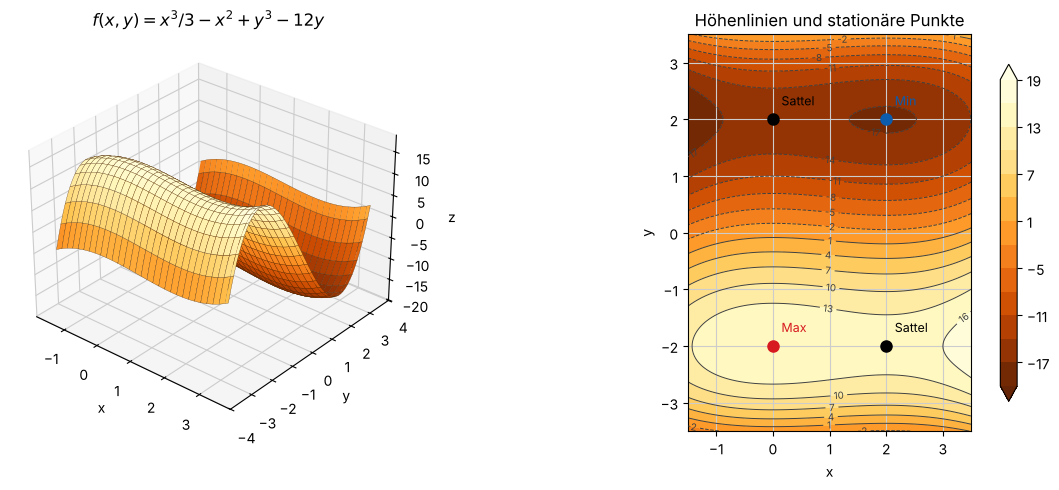

In [6]:
f289 = x**3/3 - x**2 + y**3 - 12*y
kandidaten = sp.solve([sp.diff(f289, x), sp.diff(f289, y)], [x, y], dict=True)
for k in kandidaten:
    H, ew, art = klassifiziere(f289, (k[x], k[y]))
    print(f'({k[x]!s:>2}, {k[y]!s:>2}):  Δ = {H.det()!s:>4},  f_xx = {H[0, 0]!s:>2},  f = {f289.subs(k)!s:>6}  ->  {art}')
pruefe('Hochpunkt f(0,-2) = 16', f289.subs({x: 0, y: -2}) - 16)
pruefe('Tiefpunkt f(2,2) = -52/3', f289.subs({x: 2, y: 2}) + sp.Rational(52, 3))

f289n = sp.lambdify((x, y), f289, 'numpy')
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
flaeche(f289n, (-1.5, 3.5), (-3.5, 3.5), ax=ax1, titel='$f(x,y) = x^3/3 - x^2 + y^3 - 12y$', blick=(30, -50))
ax2 = fig.add_subplot(1, 2, 2)
hoehenlinien(f289n, (-1.5, 3.5), (-3.5, 3.5), ax=ax2, niveaus=np.arange(-20, 22, 3), titel='Höhenlinien und stationäre Punkte')
for (px, py), farbe, name in [((0, -2), ROT, 'Max'), ((2, 2), BLAU, 'Min'), ((0, 2), 'k', 'Sattel'), ((2, -2), 'k', 'Sattel')]:
    ax2.plot(px, py, 'o', color=farbe, ms=8)
    ax2.annotate(name, (px, py), (px + 0.15, py + 0.25), fontsize=9, color=farbe)
plt.tight_layout(); plt.show()

## 6. Zusammenhang mit der Taylorentwicklung

Nahe einem stationären Punkt gilt mit $h = (x - x_0,\ y - y_0)^T$
$$f(x,y)\approx f(x_0,y_0) + \underbrace{\operatorname{grad} f(x_0,y_0)\cdot h}_{=\,0} + \tfrac{1}{2}\,h^TH_f(x_0,y_0)\,h.$$
Allein die quadratische Form $\tfrac{1}{2}h^THh$ entscheidet also über Maximum, Minimum oder Sattel. Die Eigenvektoren von $H$ sind die Hauptkrümmungsrichtungen, die Eigenwerte $\lambda_1,\lambda_2$ die Krümmungen, und $\Delta = \det H = \lambda_1\lambda_2$.

**Interaktiv:** Stellen Sie die Eigenwerte und die Drehung der Hauptachsen ein und beobachten Sie die Form von $q(h) = \tfrac{1}{2}h^THh$.

Output()

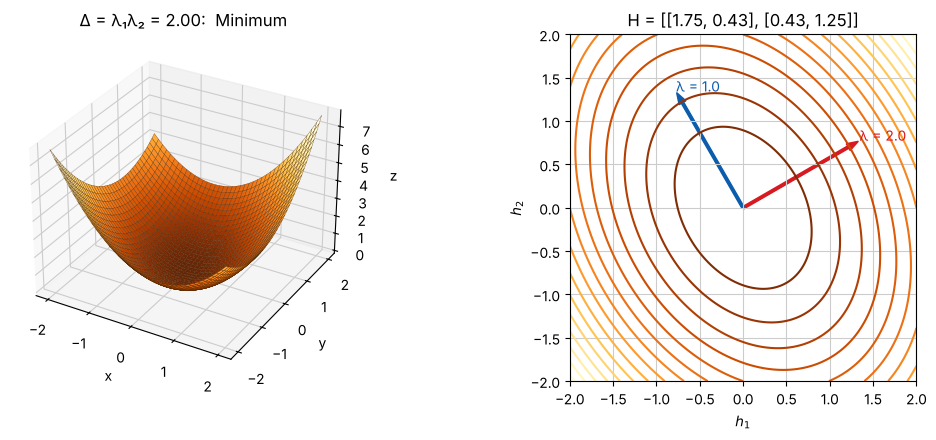

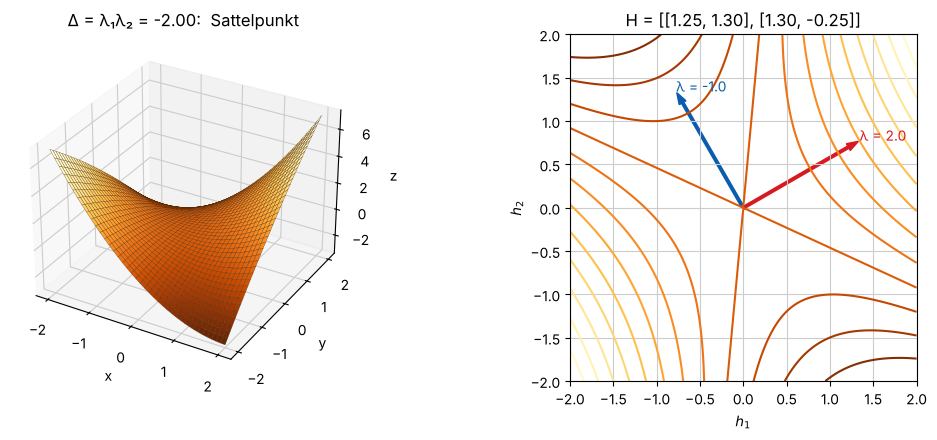

In [7]:
def zeige_quadratische_form(lam1=2.0, lam2=1.0, winkel=30):
    a = np.deg2rad(winkel)
    Q = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    H = Q @ np.diag([lam1, lam2]) @ Q.T
    q = lambda X, Y: 0.5*(H[0, 0]*X**2 + 2*H[0, 1]*X*Y + H[1, 1]*Y**2)
    D = lam1*lam2
    if D > 0:
        art = 'Minimum' if lam1 > 0 else 'Maximum'
    elif D < 0:
        art = 'Sattelpunkt'
    else:
        art = 'keine Entscheidung'
    fig = plt.figure(figsize=(11, 4.5))
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    flaeche(q, (-2, 2), (-2, 2), ax=ax1, n=40, titel=f'Δ = λ₁λ₂ = {D:.2f}:  {art}')
    ax2 = fig.add_subplot(1, 2, 2)
    X, Y = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
    ax2.contour(X, Y, q(X, Y), levels=15, cmap='YlOrBr_r')
    for v, lam, farbe in [(Q[:, 0], lam1, ROT), (Q[:, 1], lam2, BLAU)]:
        ax2.arrow(0, 0, 1.4*v[0], 1.4*v[1], width=0.03, color=farbe)
        ax2.annotate(f'λ = {lam:.1f}', (1.55*v[0], 1.55*v[1]), color=farbe)
    ax2.set(aspect='equal', xlabel='$h_1$', ylabel='$h_2$', title=f'H = [[{H[0,0]:.2f}, {H[0,1]:.2f}], [{H[1,0]:.2f}, {H[1,1]:.2f}]]')
    plt.tight_layout(); plt.show()


l1_r = widgets.FloatSlider(value=2.0, min=-3, max=3, step=0.5, description='λ₁', continuous_update=False)
l2_r = widgets.FloatSlider(value=1.0, min=-3, max=3, step=0.5, description='λ₂', continuous_update=False)
w_r = widgets.IntSlider(value=30, min=0, max=180, step=5, description='Drehung', continuous_update=False)
display(widgets.HBox([l1_r, l2_r, w_r]),
        widgets.interactive_output(zeige_quadratische_form, {'lam1': l1_r, 'lam2': l2_r, 'winkel': w_r}))

# Statische Vorschau für GitHub: Minimum und Sattelpunkt.
zeige_quadratische_form(2.0, 1.0, 30)
zeige_quadratische_form(2.0, -1.0, 30)

## 7. Satz 2.8.1.10 (Hurwitz-Kriterium) und Beispiel 2.8.1.11

Für $n\ge 3$ ist die Berechnung der Eigenwerte oft mühsam. Mit den **Hauptminoren** $H_k$ (Determinante der linken oberen $k\times k$-Teilmatrix) einer symmetrischen Matrix $H$ gilt:

* $H$ positiv definit $\iff H_1 > 0,\ H_2 > 0,\ \dots,\ H_n > 0$,
* $H$ negativ definit $\iff (-1)^kH_k > 0$ für alle $k$ (Vorzeichen $-,+,-,\dots$),
* ist $\det H\neq 0$ und trifft keines davon zu, so ist $H$ indefinit.

Für $n = 2$ ist $H_1 = f_{xx}$ und $H_2 = \Delta$: Das ist Satz 2.8.1.8.

**Beispiel 2.8.1.11:** $f(x,y,z) = x^2 + y^2 + z^2 + xy + yz - x - z$. Aus $f_x = 2x + y - 1 = 0$, $f_y = x + 2y + z = 0$, $f_z = y + 2z - 1 = 0$ folgt der einzige stationäre Punkt $(1,-1,1)$. Die Hesse-Matrix
$$H_f = \begin{pmatrix} 2 & 1 & 0\\ 1 & 2 & 1\\ 0 & 1 & 2\end{pmatrix}$$
hat die Hauptminoren $H_1 = 2$, $H_2 = 3$, $H_3 = 4$, alle positiv: lokales (wegen der konstanten Hesse-Matrix sogar globales) Minimum mit $f(1,-1,1) = -1$.

In [8]:
def hauptminoren(H):
    return [H[:k, :k].det() for k in range(1, H.shape[0] + 1)]


f2811 = x**2 + y**2 + z**2 + x*y + y*z - x - z
stat = sp.solve([sp.diff(f2811, v) for v in (x, y, z)], [x, y, z], dict=True)
print('stationäre Punkte:', stat)
H = sp.hessian(f2811, (x, y, z))
display(H)
print('Hauptminoren:', hauptminoren(H), '  Eigenwerte:', list(H.eigenvals(multiple=True)))
pruefe('stationärer Punkt (1,-1,1)', sp.Matrix([stat[0][v] for v in (x, y, z)]) - sp.Matrix([1, -1, 1]))
pruefe('Hauptminoren 2, 3, 4', sp.Matrix(hauptminoren(H)) - sp.Matrix([2, 3, 4]))
pruefe('f(1,-1,1) = -1', f2811.subs(stat[0]) + 1)

# Gegenprobe: eine indefinite und eine negativ definite Matrix
for name, A in [('indefinit', sp.Matrix([[1, 2, 0], [2, 1, 0], [0, 0, 3]])), ('negativ definit', -H)]:
    print(f'{name:16s} Hauptminoren {hauptminoren(A)}  Eigenwerte {[sp.nsimplify(e) for e in A.eigenvals(multiple=True)]}')

stationäre Punkte: [{x: 1, y: -1, z: 1}]


⎡2  1  0⎤
⎢       ⎥
⎢1  2  1⎥
⎢       ⎥
⎣0  1  2⎦

Hauptminoren: [2, 3, 4]   Eigenwerte: [2, sqrt(2) + 2, 2 - sqrt(2)]
Probe stationärer Punkt (1,-1,1): Residuum = Matrix([[0], [0], [0]])  -> ok
Probe Hauptminoren 2, 3, 4: Residuum = Matrix([[0], [0], [0]])  -> ok
Probe f(1,-1,1) = -1: Residuum = 0  -> ok
indefinit        Hauptminoren [1, -3, -9]  Eigenwerte [-1, 3, 3]
negativ definit  Hauptminoren [-2, 3, -4]  Eigenwerte [-2, -2 + sqrt(2), -2 - sqrt(2)]


## 8. Satz 2.8.1.12 (Weierstraß) und Beispiel 2.8.1.13: Extrema auf dem Rand

Ist $D\subseteq\mathbb{R}^n$ **kompakt** (abgeschlossen und beschränkt) und $f$ stetig, so hat $f$ auf $D$ ein globales Maximum und Minimum. Die Bedingung $\operatorname{grad} f = 0$ gilt aber nur in **inneren** Punkten. Man vergleicht deshalb die Werte in den stationären Punkten im Inneren, in den Extremstellen auf dem Rand und in den Ecken.

**Beispiel 2.8.1.13:** $f(x,y) = x^2 - 2xy + 2y$ auf $D = [0,3]\times[0,2]$.

* Inneres: $(1,1)$ mit $f = 1$ (Sattelpunkt, $\Delta = -4$).
* Rand: $y = 0$: $f = x^2$; $x = 3$: $f = 9 - 4y$; $y = 2$: $f = (x-2)^2$; $x = 0$: $f = 2y$.

Globales Maximum $f(3,0) = 9$, globales Minimum $f(0,0) = f(2,2) = 0$, alle auf dem Rand mit $\operatorname{grad} f\neq 0$.

f(0, 0) =   0   (Rand unten, grad f = [0, 2])
f(2, 2) =   0   (Rand oben, grad f = [0, -2])
f(1, 1) =   1   (innen, grad f = [0, 0])
f(3, 2) =   1   (Rand rechts, grad f = [2, -4])
f(0, 2) =   4   (Rand oben, grad f = [-4, 2])
f(3, 0) =   9   (Rand unten, grad f = [6, -4])
Probe globales Maximum 9: Residuum = 0  -> ok
Probe globales Minimum 0: Residuum = 0  -> ok


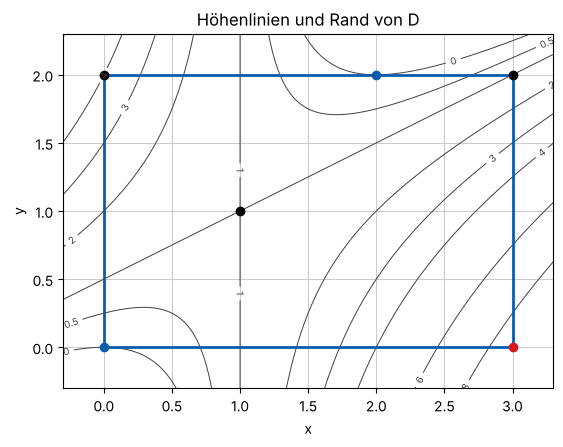

In [9]:
f2813 = x**2 - 2*x*y + 2*y
t = sp.symbols('t', real=True)
kandidaten = {}
for p in sp.solve([sp.diff(f2813, x), sp.diff(f2813, y)], [x, y], dict=True):
    if 0 < p[x] < 3 and 0 < p[y] < 2:
        kandidaten[(p[x], p[y])] = 'innen'
# Randstücke als Funktionen einer Variablen: (x(t), y(t), t-Bereich)
for name, (xt, yt, a_, b_) in {'unten': (t, 0, 0, 3), 'rechts': (3, t, 0, 2), 'oben': (t, 2, 0, 3), 'links': (0, t, 0, 2)}.items():
    g = f2813.subs({x: xt, y: yt})
    for t0 in [a_, b_] + [s for s in sp.solve(sp.diff(g, t), t) if a_ < s < b_]:
        kandidaten.setdefault((sp.sympify(xt).subs(t, t0), sp.sympify(yt).subs(t, t0)), 'Rand ' + name)
werte = sorted(((f2813.subs({x: px, y: py}), (px, py), wo) for (px, py), wo in kandidaten.items()), key=lambda w: w[0])
for w, p, wo in werte:
    gr = [sp.diff(f2813, v).subs({x: p[0], y: p[1]}) for v in (x, y)]
    print(f'f{p} = {w!s:>3}   ({wo}, grad f = {gr})')
pruefe('globales Maximum 9', werte[-1][0] - 9)
pruefe('globales Minimum 0', werte[0][0])

fn = sp.lambdify((x, y), f2813, 'numpy')
fig, ax = plt.subplots(figsize=(6.5, 4.6))
hoehenlinien(fn, (-0.3, 3.3), (-0.3, 2.3), ax=ax, niveaus=[0, 0.5, 1, 2, 3, 4, 6, 8], titel='Höhenlinien und Rand von D', gefuellt=False)
ax.plot([0, 3, 3, 0, 0], [0, 0, 2, 2, 0], color=BLAU, lw=2)
for w, p, wo in werte:
    farbe = ROT if w == 9 else (BLAU if w == 0 else 'k')
    ax.plot(float(p[0]), float(p[1]), 'o', color=farbe, ms=6)
plt.show()